# Task 5: Account Security Monitoring — Final V7-A Pure Unsupervised Pipeline

**CPE342 Machine Learning (1/2026) — Team ML009**
- **Task:** Unsupervised Anomaly Detection (`0 = Normal`, `1 = Anomalous`) on `data/task5/test.csv` (`25,889 rows x 123 cols`)
- **Evaluation Metric:** $F_3$-Score ($F_3 = \frac{10 \cdot P \cdot R}{9P + R}$, weights Recall 9x higher than Precision)
- **Competition Rule Compliance:**
  - Strictly unsupervised learning on `data/task5/test.csv` from scratch (no external data, no labels, no AutoML, **zero hard-coded rule overrides**)
- **Final V7-A Multi-Paradigm Architecture:**
  1. Multi-View & Bridged-Geolocation Feature Engineering (`geo_12..34` + bridged `geo_13/24/14` in Euclidean & Haversine km + 1D axis deltas) + 5x Block-Permuted Independent Null
  2. Multi-Bandwidth 1D Topological Valley-Rebound KDE (**V7-A Unclipped Histogram + Poisson Island Significance $Z \ge 2.0$**, calibrated via 3-Component GMM)
  3. Focused 3D Combat Subspace Density Ratios & 1-Step EM-Debiased 3D KDE (`Residual Topological Exclusion` masking `p_topo >= 0.50`) + Multi-Subspace LightGBM OOF Density Ratios
  4. **Unsupervised Mixture-MICE Cross-Feature `NaN` Recovery** calibrated via 5-Fold OOF `IsotonicRegression` (`behavior_stability` `OOF ROC-AUC = 0.9816`, Bridged Geo/Period-4 `0.9946–1.0000`)
  5. Classical Ensemble (`IsolationForest`, `NearestNeighbors(k=20)`, Temporal `L2/Max`, `MLPRegressor((64,16,64))` Autoencoder) fused via **Probabilistic Noisy-OR** & **Bayes Expected-$F_3$ Cutoff** (`2,163` flagged / `8.35%`, Kaggle LB **`0.83611`**)

## 1. Environment Setup, Paths & Multi-View Feature Engineering

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.ndimage import gaussian_filter
from scipy.signal import fftconvolve
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler, StandardScaler

SEED = 42
np.random.seed(SEED)

cwd = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(cwd, "data", "task5", "test.csv")):
    BASE_DIR = cwd
elif os.path.exists(os.path.join(os.path.dirname(cwd), "data", "task5", "test.csv")):
    BASE_DIR = os.path.dirname(cwd)
else:
    BASE_DIR = os.path.dirname(cwd) if os.path.basename(cwd) == "task5" else cwd

DATA_DIR = os.path.join(BASE_DIR, "data", "task5")
SUB_DIR = os.path.join(BASE_DIR, "submissions")
os.makedirs(SUB_DIR, exist_ok=True)
print(f"BASE_DIR : {BASE_DIR}")
print(f"DATA_DIR : {DATA_DIR}")

STATIC_COLS = [
    "account_age_days",
    "behavior_stability",
    "password_changed",
    "vpn_usage",
    "suspicious_login_time",
    "mass_item_sale",
]
COMBAT_3D_COLS = [
    "accuracy_std_mean",
    "kda_std_mean",
    "performance_stability_mean",
]


def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate great-circle distance in kilometers using the Haversine formula."""
    r_lat1 = np.radians(np.clip(lat1, -90.0, 90.0))
    r_lat2 = np.radians(np.clip(lat2, -90.0, 90.0))
    dlat = np.radians(np.clip(lat2, -90.0, 90.0) - np.clip(lat1, -90.0, 90.0))
    dlon_raw = np.abs(lon2 - lon1)
    dlon = np.radians(np.minimum(dlon_raw, 360.0 - (dlon_raw % 360.0)))
    a = np.sin(dlat / 2.0) ** 2 + np.cos(r_lat1) * np.cos(r_lat2) * np.sin(dlon / 2.0) ** 2
    return 2.0 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


def get_temporal_bases(df: pd.DataFrame) -> list[str]:
    return sorted({c[:-2] for c in df.columns[1:] if c.endswith(("_1", "_2", "_3", "_4"))})


def build_multiview_features(
    df: pd.DataFrame,
    bases: list[str],
    mad_ref: dict[str, float] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, float]]:
    """Construct Profile, Temporal-Delta, and Bridged-Geolocation feature views."""
    prof: dict[str, pd.Series | np.ndarray] = {}
    delt: dict[str, pd.Series | np.ndarray] = {}
    new_mad: dict[str, float] = {}

    for b in bases:
        cols = [f"{b}_{i}" for i in range(1, 5)]
        vals = df[cols]
        prof[f"{b}_mean"] = vals.mean(axis=1)
        prof[f"{b}_std"] = vals.std(axis=1)

        if mad_ref is None:
            d21 = (df[f"{b}_2"] - df[f"{b}_1"]).dropna()
            mad21 = float(np.median(np.abs(d21 - np.median(d21))) * 1.4826)
            if mad21 < 1e-6:
                mad21 = float(d21.std() + 1e-6)
            new_mad[b] = mad21
        else:
            mad21 = mad_ref[b]

        delt[f"{b}_d4"] = (df[f"{b}_4"] - df[[f"{b}_1", f"{b}_2", f"{b}_3"]].mean(axis=1)) / mad21
        delt[f"{b}_d3"] = (df[f"{b}_3"] - df[[f"{b}_1", f"{b}_2"]].mean(axis=1)) / mad21
        delt[f"{b}_d2"] = (df[f"{b}_2"] - df[f"{b}_1"]) / mad21
        delt[f"{b}_p4m1"] = (df[f"{b}_4"] - df[f"{b}_1"]) / mad21
        delt[f"{b}_p4"] = df[f"{b}_4"]

    for a, b in [(1, 2), (2, 3), (3, 4), (1, 3), (2, 4), (1, 4)]:
        delt[f"geo_{a}{b}"] = np.sqrt(
            (df[f"login_lat_{b}"] - df[f"login_lat_{a}"]) ** 2
            + (df[f"login_lon_{b}"] - df[f"login_lon_{a}"]) ** 2
        )
        delt[f"geo_km_{a}{b}"] = haversine_km(
            df[f"login_lat_{a}"], df[f"login_lon_{a}"],
            df[f"login_lat_{b}"], df[f"login_lon_{b}"],
        )
        delt[f"dlat_{a}{b}"] = np.abs(df[f"login_lat_{b}"] - df[f"login_lat_{a}"])
        delt[f"dlon_{a}{b}"] = np.abs(df[f"login_lon_{b}"] - df[f"login_lon_{a}"])

    delt["geo_max"] = np.nanmax(
        np.vstack([delt["geo_12"], delt["geo_23"], delt["geo_34"], delt["geo_13"], delt["geo_24"]]), axis=0
    )
    delt["geo_km_max"] = np.nanmax(
        np.vstack([delt["geo_km_12"], delt["geo_km_23"], delt["geo_km_34"], delt["geo_km_13"], delt["geo_km_24"]]), axis=0
    )
    delt["geo_1d_max"] = np.nanmax(
        np.vstack([delt["dlat_23"], delt["dlon_23"], delt["dlat_34"], delt["dlon_34"], delt["dlat_24"], delt["dlon_24"]]), axis=0
    )

    for c in STATIC_COLS:
        prof[c] = df[c]
    for c in ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]:
        delt[c] = df[c]

    prof["inactivity_vs_skill"] = prof["skill_rating_mean"] / (prof["activity_level_mean"] + 0.05)
    prof["inactivity_vs_spend"] = prof["purchase_amount_mean_mean"] / (prof["activity_level_mean"] + 0.05)
    prof["combat_inconsistency"] = (prof["accuracy_std_mean"] * prof["kda_std_mean"]) * prof["performance_stability_mean"]
    prof["spam_ratio"] = (
        prof["friend_adds_mean"] + prof["friend_removes_mean"] + prof["guild_changes_mean"]
    ) / (prof["communication_frequency_mean"] + 0.05)
    prof["bot_regularity"] = (
        (1.0 - np.clip(prof["ip_hash_entropy_mean"], 0.0, 1.0))
        * (1.0 - np.clip(prof["login_time_variance_mean"], 0.0, 10.0) / 10.0)
        / (prof["session_duration_std_mean"] + 0.1)
    )

    delt["takeover_intensity"] = (
        np.maximum(0.0, delt["currency_transfers_d4"]) * (1.0 + df["password_changed"].fillna(0) + df["mass_item_sale"].fillna(0))
        + np.nan_to_num(delt["geo_km_34"], nan=0.0) / 1000.0 * (1.0 + df["password_changed"].fillna(0))
    )
    delt["boosting_intensity"] = (
        np.maximum(0.0, delt["skill_trajectory_d4"])
        + np.maximum(0.0, delt["skill_rating_d4"])
        + np.maximum(0.0, delt["friend_removes_d4"])
    )
    delt["vpn_intensity"] = (
        (1.0 + df["vpn_usage"].fillna(0))
        * (np.nan_to_num(delt["geo_max"], nan=0.0) + np.nan_to_num(delt["geo_1d_max"], nan=0.0))
        * (1.0 + np.maximum(0.0, delt["purchase_frequency_d4"]))
    )

    return (
        pd.DataFrame(prof, index=df.index),
        pd.DataFrame(delt, index=df.index),
        new_mad if mad_ref is None else mad_ref,
    )


def generate_block_permuted_null(
    df: pd.DataFrame,
    bases: list[str],
    mad_ref: dict[str, float],
    n_repeats: int = 5,
    seed: int = SEED,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Permute temporal blocks and static columns independently to construct empirical null distribution."""
    rng = np.random.default_rng(seed)
    perm_profs, perm_delts = [], []
    for _ in range(n_repeats):
        pr = df.iloc[:, 1:].copy()
        for b in bases:
            pcols = [f"{b}_{i}" for i in range(1, 5)]
            idx = rng.permutation(len(pr))
            pr[pcols] = pr[pcols].iloc[idx].to_numpy()
        for c in STATIC_COLS:
            idx = rng.permutation(len(pr))
            pr[c] = pr[c].iloc[idx].to_numpy()
        pp, pdlt, _ = build_multiview_features(pr, bases, mad_ref=mad_ref)
        perm_profs.append(pp)
        perm_delts.append(pdlt)
    return pd.concat(perm_profs, axis=0, ignore_index=True), pd.concat(perm_delts, axis=0, ignore_index=True)

BASE_DIR : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009
DATA_DIR : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\data\task5


## 2. V7-A Detectors: Unclipped 1D Topological KDE, 3D Combat KDE/DR & Mixture-MICE

In [2]:
def compute_1d_topological_valley_kde(
    series_vals: pd.Series | np.ndarray,
    bw_factor: float = 0.08,
    min_island_z: float = 2.0,
) -> tuple[np.ndarray, np.ndarray]:
    """V7-A topological 1D anomaly detector using unclipped histogram & Poisson island Z >= 2.0."""
    v = np.asarray(series_vals, dtype=float)
    ok = ~np.isnan(v)
    if ok.sum() < 100:
        return np.zeros(len(v)), np.zeros(len(v))
    vo = v[ok]
    if len(np.unique(vo)) <= 25:
        return np.zeros(len(v)), np.zeros(len(v))
    iqr = float(np.quantile(vo, 0.75) - np.quantile(vo, 0.25))
    if iqr < 1e-9:
        return np.zeros(len(v)), np.zeros(len(v))

    bw = bw_factor * iqr
    lo, hi = float(np.quantile(vo, 0.0005)), float(np.quantile(vo, 0.9995))
    if hi <= lo:
        return np.zeros(len(v)), np.zeros(len(v))

    n_grid = 1024
    edges = np.linspace(lo - 2.0 * bw, hi + 2.0 * bw, n_grid + 1)
    dx = (edges[-1] - edges[0]) / n_grid
    counts, _ = np.histogram(vo, bins=edges)
    n_win = max(float(counts.sum()), 1.0)
    sigma_bins = max(1.0, bw / dx)
    kx = np.arange(-int(4 * sigma_bins), int(4 * sigma_bins) + 1)
    kern = np.exp(-0.5 * (kx / sigma_bins) ** 2)
    kern /= kern.sum()
    dens = fftconvolve(counts.astype(float), kern, mode="same") / (n_win * dx)
    log_d = np.log(np.maximum(dens, 1e-12))

    mode_idx = int(np.argmax(log_d))
    mode_log_d = log_d[mode_idx]
    path_min = np.zeros(n_grid)
    path_min[mode_idx] = log_d[mode_idx]
    for i in range(mode_idx + 1, n_grid):
        path_min[i] = min(path_min[i - 1], log_d[i])
    for i in range(mode_idx - 1, -1, -1):
        path_min[i] = min(path_min[i + 1], log_d[i])

    valley_drop = np.maximum(0.0, mode_log_d - path_min)
    reb_raw = np.maximum(0.0, log_d - path_min)
    rebound = np.zeros(n_grid)
    is_pos = reb_raw > 1e-4
    i = 0
    while i < n_grid:
        if is_pos[i]:
            j = i
            while j < n_grid and is_pos[j]:
                j += 1
            isl_n = float(counts[i:j].sum())
            exp_val = float(np.sum(np.exp(path_min[i:j]) * n_win * dx))
            z_isl = (isl_n - exp_val) / np.sqrt(isl_n + exp_val + 1.0)
            if z_isl >= min_island_z:
                rebound[i:j] = reb_raw[i:j]
            i = j
        else:
            i += 1

    vc = np.clip(vo, edges[0], edges[-1])
    g_idx = np.clip(np.searchsorted(edges[1:-1], vc, side="right"), 0, n_grid - 1)
    s_drop = np.zeros(len(v))
    s_reb = np.zeros(len(v))
    s_drop[ok] = valley_drop[g_idx]
    s_reb[ok] = rebound[g_idx]
    return s_drop, s_reb


def fit_lgb_oof_density_ratio(
    X_real: pd.DataFrame,
    X_perm: pd.DataFrame,
    cols: list[str],
    n_rep: int = 4,
    n_estimators: int = 180,
    num_leaves: int = 31,
    n_splits: int = 5,
) -> tuple[np.ndarray, np.ndarray]:
    """Out-of-fold density ratio log(p_real / p_perm) and excess anomaly probability."""
    Xr = X_real[cols].reset_index(drop=True)
    n = len(Xr)
    Xp = X_perm[cols].iloc[: n_rep * n].reset_index(drop=True)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    probs = np.zeros(n)

    for tr, va in kf.split(Xr):
        tr_p = np.concatenate([tr + k * n for k in range(n_rep)])
        X_tr = pd.concat([Xr.iloc[tr], Xp.iloc[tr_p]], axis=0, ignore_index=True)
        y_tr = np.concatenate([np.ones(len(tr), dtype=int), np.zeros(len(tr_p), dtype=int)])
        w_tr = np.concatenate([np.full(len(tr), float(n_rep)), np.ones(len(tr_p))])
        clf = lgb.LGBMClassifier(
            n_estimators=n_estimators, learning_rate=0.055, num_leaves=num_leaves,
            min_child_samples=25, subsample=0.85, colsample_bytree=0.9,
            reg_lambda=2.0, random_state=SEED, verbose=-1, n_jobs=4,
        )
        clf.fit(X_tr, y_tr, sample_weight=w_tr)
        probs[va] = np.clip(clf.predict_proba(Xr.iloc[va])[:, 1], 1e-6, 1.0 - 1e-6)

    ratio = probs / (1.0 - probs)
    log_odds = np.log(ratio)
    p_excess = np.clip((ratio - 1.0) / np.maximum(ratio, 1e-9), 0.0, 1.0)
    return log_odds, p_excess


def compute_debiased_3d_kde_posterior(
    X3_df: pd.DataFrame,
    prelim_anom_prob: np.ndarray,
    exclude_mask: np.ndarray | None = None,
    bw: float = 0.24,
    nbins: int = 80,
) -> np.ndarray:
    """1-Step EM-debiased 3D Gaussian-filtered KDE density ratio with topological exclusion."""
    X3 = X3_df.to_numpy(dtype=float)
    s3 = (np.nanpercentile(X3, 75, axis=0) - np.nanpercentile(X3, 25, axis=0)) / 1.349
    s3 = np.where(s3 < 1e-9, 1.0, s3)
    X3s = (X3 - np.nanmedian(X3, axis=0)) / s3

    lo3 = np.nanquantile(X3s, 0.0005, axis=0) - 0.5
    hi3 = np.nanquantile(X3s, 0.9995, axis=0) + 0.5
    edges3 = [np.linspace(lo3[d], hi3[d], nbins + 1) for d in range(3)]
    X3c = np.clip(X3s, lo3, hi3 - 1e-9)
    ok3 = ~np.isnan(X3c).any(axis=1)
    fit_ok = ok3 if exclude_mask is None else (ok3 & (~exclude_mask))

    hist_3d, _ = np.histogramdd(X3c[fit_ok], bins=edges3)
    sigmas = [bw / ((hi3[d] - lo3[d]) / nbins) for d in range(3)]
    p_joint_grid = np.maximum(gaussian_filter(hist_3d, sigma=sigmas, mode="nearest") / max(hist_3d.sum(), 1.0), 1e-12)

    w_clean = np.clip(1.0 - prelim_anom_prob[fit_ok], 0.02, 1.0)
    p_marg_1d = []
    for d in range(3):
        h1, _ = np.histogram(X3c[fit_ok, d], bins=edges3[d], weights=w_clean)
        h1s = gaussian_filter(h1, sigma=sigmas[d], mode="nearest")
        p_marg_1d.append(np.maximum(h1s / max(h1.sum(), 1e-9), 1e-12))

    idx3 = [np.clip(np.searchsorted(edges3[d][1:-1], X3c[:, d], side="right"), 0, nbins - 1) for d in range(3)]
    pj = p_joint_grid[idx3[0], idx3[1], idx3[2]]
    pm = p_marg_1d[0][idx3[0]] * p_marg_1d[1][idx3[1]] * p_marg_1d[2][idx3[2]]
    ratio = np.where(fit_ok, pj / np.maximum(pm, 1e-12), 1.0)
    return np.clip((ratio - 1.0) / np.maximum(ratio, 1e-9), 0.0, 1.0)


def fit_unsupervised_mixture_mice_recovery(
    X_summary: pd.DataFrame,
    topo_feats: dict[str, pd.Series | np.ndarray],
    topo_names: list[str],
    ve_mat: np.ndarray,
) -> tuple[np.ndarray, pd.Series | None]:
    """Unsupervised Mixture-MICE NaN recovery via peer cross-feature OOF classifiers + Isotonic calibration."""
    n = len(X_summary)
    na_recovery_prob = np.zeros(n)
    imputed_bs = X_summary["behavior_stability"].copy() if "behavior_stability" in X_summary else None

    for j, cname in enumerate(topo_names):
        if cname.endswith("_p4") and f"{cname[:-3]}_d4" in topo_names:
            continue
        s_raw = pd.Series(topo_feats[cname], index=X_summary.index)
        na_rate = float(s_raw.isna().mean())
        if not (0.01 < na_rate < 0.25):
            continue
        ve_col = ve_mat[:, j]
        min_flag_all = (ve_col >= 8.5)
        obs_m = s_raw.notna().to_numpy()
        y_obs = min_flag_all[obs_m].astype(int)
        if y_obs.sum() < 120 or y_obs.sum() > 1500:
            continue

        base_prefix = cname.split("_mean")[0].split("_d4")[0]
        if cname.startswith(("geo_", "dlat_", "dlon_")):
            drop_c = [c for c in X_summary.columns if c.startswith(("geo_", "dlat_", "dlon_"))]
        else:
            drop_c = [c for c in X_summary.columns if c == cname or c.startswith(base_prefix + "_")]
        X_sub = X_summary.drop(columns=drop_c, errors="ignore")

        obs_idx = np.where(obs_m)[0]
        na_idx = np.where(~obs_m)[0]
        oof_rec = np.zeros(len(obs_idx))
        na_rec = np.zeros(len(na_idx))

        kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
        for tr_s, va_s in kf.split(obs_idx):
            clf = lgb.LGBMClassifier(
                n_estimators=120, learning_rate=0.05, num_leaves=15,
                min_child_samples=25, subsample=0.85, colsample_bytree=0.85,
                reg_lambda=2.0, random_state=SEED, verbose=-1, n_jobs=4,
            )
            clf.fit(X_sub.iloc[obs_idx[tr_s]], y_obs[tr_s])
            oof_rec[va_s] = clf.predict_proba(X_sub.iloc[obs_idx[va_s]])[:, 1]
            na_rec += clf.predict_proba(X_sub.iloc[na_idx])[:, 1] / 5.0

        auc_rec = float(roc_auc_score(y_obs, oof_rec))
        iso_cal = IsotonicRegression(out_of_bounds="clip").fit(oof_rec, y_obs)
        p_na_cal = iso_cal.transform(na_rec)

        if auc_rec >= 0.92:
            p_na_ex = np.where(p_na_cal >= 0.15, p_na_cal, 0.0)
            na_recovery_prob[na_idx] = np.maximum(na_recovery_prob[na_idx], p_na_ex)
            rec_cnt = int((p_na_ex >= 0.15).sum())
            print(f"  Mixture-MICE [{cname:<27s}] NaN={len(na_idx):4d} | Mode={y_obs.sum():3d} | OOF AUC={auc_rec:.4f} | Recovered(>=0.15)={rec_cnt:3d}")

            if cname == "behavior_stability" and imputed_bs is not None:
                low_med = float(np.median(s_raw.iloc[obs_idx][y_obs == 1]))
                hi_med = float(np.median(s_raw.iloc[obs_idx][y_obs == 0]))
                imputed_bs.iloc[na_idx] = p_na_cal * low_med + (1.0 - p_na_cal) * hi_med

    return na_recovery_prob, imputed_bs


def to_mad_z(scores: np.ndarray) -> np.ndarray:
    med = np.median(scores)
    mad = np.median(np.abs(scores - med)) * 1.4826
    if mad < 1e-6:
        mad = np.std(scores) + 1e-6
    return np.maximum(0.0, (scores - med) / mad)

## 3. Execute V7-A Pipeline, Noisy-OR Fusion & Bayes Expected-F3 Thresholding

In [3]:
t0 = time.time()
print("=" * 74)
print("Task 5: Rule-Compliant Pure Unsupervised Multi-Paradigm Pipeline (V7-A)")
print("=" * 74)

test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(BASE_DIR, "data", "sample_submission.csv"))
bases = get_temporal_bases(test_df)
cont_bases = [b for b in bases if test_df[f"{b}_1"].dropna().nunique() > 25]
n = len(test_df)
print(f"Loaded test.csv: {n:,} rows x {test_df.shape[1]} cols ({len(bases)} bases, {len(cont_bases)} continuous)")

# 1. Multi-View Feature Engineering & Block-Permuted Null Copy
prof_df, delt_df, mad_ref = build_multiview_features(test_df, bases)
prof_perm, delt_perm = generate_block_permuted_null(test_df, bases, mad_ref, n_repeats=5, seed=SEED)
print(f"[1/5] Multi-view features & 5x block-permuted null built ({time.time() - t0:.1f}s)")

# 2. Multi-Bandwidth 1D Topological Valley-Rebound KDE Detector (V7-A Poisson Z >= 2.0)
topo_feats = {}
for b in cont_bases:
    topo_feats[f"{b}_mean"] = prof_df[f"{b}_mean"]
    topo_feats[f"{b}_d4"] = delt_df[f"{b}_d4"]
    topo_feats[f"{b}_p4"] = delt_df[f"{b}_p4"]
topo_feats["behavior_stability"] = test_df["behavior_stability"]
topo_feats["account_age_days"] = test_df["account_age_days"]
for g in ["geo_12", "geo_23", "geo_34", "geo_13", "geo_24", "dlat_23", "dlon_23", "dlat_34", "dlon_34"]:
    topo_feats[g] = delt_df[g]

topo_names = list(topo_feats.keys())
ve_mat = np.zeros((n, len(topo_names)))
for j, k in enumerate(topo_names):
    sd1, sr1 = compute_1d_topological_valley_kde(topo_feats[k], bw_factor=0.075)
    sd2, sr2 = compute_1d_topological_valley_kde(topo_feats[k], bw_factor=0.115)
    sd = np.minimum(sd1, sd2)
    sr = np.minimum(sr1, sr2)
    ve_mat[:, j] = np.where(sr > 0.25, sd * np.minimum(sr + 0.5, 4.0), 0.25 * sd)
topo_max_ve = ve_mat.max(axis=1)

t_log = np.log1p(topo_max_ve)
gmm_t = GaussianMixture(n_components=3, covariance_type="full", random_state=SEED).fit(t_log.reshape(-1, 1))
bulk_comp = int(np.argmin(gmm_t.means_.ravel()))
p_topo = 1.0 - gmm_t.predict_proba(t_log.reshape(-1, 1))[:, bulk_comp]
print(f"[2/5] 1D Topological Valley KDE calibrated (3-GMM bulk={gmm_t.means_.ravel()[bulk_comp]:.2f}) ({time.time() - t0:.1f}s)")

# 3. Focused Subspace Density Ratios + 1-Step EM-Debiased 3D Gaussian KDE Ratio
topo_core_mask = p_topo >= 0.50
_, p_ex_c3 = fit_lgb_oof_density_ratio(prof_df, prof_perm, COMBAT_3D_COLS, n_rep=5, n_estimators=180, num_leaves=15)
p_kde_c3 = compute_debiased_3d_kde_posterior(prof_df[COMBAT_3D_COLS], p_ex_c3, exclude_mask=topo_core_mask, bw=0.24, nbins=80)
p_combat = 0.5 * p_ex_c3 + 0.5 * p_kde_c3

prof_core_cols = [
    "behavior_stability", "purchase_frequency_mean", "purchase_frequency_std", "login_count_mean", "account_age_days",
    "activity_level_mean", "skill_rating_mean", "skill_rating_std", "purchase_amount_mean_mean",
    "communication_frequency_mean", "friend_adds_mean", "guild_changes_mean",
    "ip_hash_entropy_mean", "login_time_variance_mean", "session_duration_std_mean", "device_count_std", "kda_std_mean",
    "play_pattern_consistency_mean", "performance_stability_mean",
    "inactivity_vs_skill", "inactivity_vs_spend", "bot_regularity", "spam_ratio",
]
lo_prof_core, _ = fit_lgb_oof_density_ratio(prof_df, prof_perm, prof_core_cols, n_rep=4, n_estimators=180, num_leaves=31)
lo_prof_all, _ = fit_lgb_oof_density_ratio(prof_df, prof_perm, list(prof_df.columns), n_rep=2, n_estimators=180, num_leaves=31)
delt_focus_cols = [
    c for c in delt_df.columns
    if c.endswith(("_d4", "_d3", "_p4")) or c.startswith(("geo_", "dlat_", "dlon_")) or c in [
        "password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale",
        "takeover_intensity", "boosting_intensity", "vpn_intensity",
    ]
]
lo_delt, _ = fit_lgb_oof_density_ratio(delt_df, delt_perm, delt_focus_cols, n_rep=3, n_estimators=180, num_leaves=31)
print(f"[3/5] Subspace OOF Density Ratios + 3D Combat KDE ready ({time.time() - t0:.1f}s)")

# 4. Unsupervised Mixture-MICE NaN Recovery
X_summ = pd.concat([
    prof_df,
    delt_df[[
        c for c in delt_df.columns
        if c.endswith("_d4") or c.startswith(("geo_", "dlat_", "dlon_"))
        or c in ["password_changed", "vpn_usage", "mass_item_sale", "suspicious_login_time"]
    ]],
], axis=1)
X_summ = X_summ.loc[:, ~X_summ.columns.duplicated()]
print("[4/5] Running Unsupervised Mixture-MICE cross-feature NaN recovery...")
na_recovery_prob, imputed_bs = fit_unsupervised_mixture_mice_recovery(X_summ, topo_feats, topo_names, ve_mat)

# 5. Classical Unsupervised Ensemble + Noisy-OR Fusion + Bayes Expected-F3 Cutoff
prof_for_geom = prof_df.copy()
if imputed_bs is not None:
    prof_for_geom["behavior_stability"] = imputed_bs

cont_ms_cols = [f"{b}_mean" for b in bases] + ["account_age_days", "behavior_stability"]
X_prof_rob = np.clip(RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(prof_for_geom[cont_ms_cols])), -15.0, 15.0)
s_iso_prof = -IsolationForest(n_estimators=250, max_samples=512, contamination="auto", random_state=SEED, n_jobs=4).fit(X_prof_rob).score_samples(X_prof_rob)

delt_cont_cols = [c for c in delt_focus_cols if c not in ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]]
X_dc_rob = np.clip(RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(delt_df[delt_cont_cols])), -20.0, 20.0)
s_iso_delt = -IsolationForest(n_estimators=250, max_samples=512, contamination="auto", random_state=SEED, n_jobs=4).fit(X_dc_rob).score_samples(X_dc_rob)
s_delt_l2 = np.sqrt(np.mean(X_dc_rob ** 2, axis=1))
s_delt_max = np.max(np.abs(X_dc_rob), axis=1)

X_comb = StandardScaler().fit_transform(np.hstack([X_prof_rob, X_dc_rob]))
ae = MLPRegressor(hidden_layer_sizes=(64, 16, 64), max_iter=50, early_stopping=True, random_state=SEED).fit(X_comb, X_comb)
s_ae = np.mean((X_comb - ae.predict(X_comb)) ** 2, axis=1)

nn = NearestNeighbors(n_neighbors=20, n_jobs=4).fit(X_prof_rob)
s_knn = nn.kneighbors(X_prof_rob)[0].mean(axis=1)

views_global = np.vstack([
    to_mad_z(lo_prof_core),
    to_mad_z(lo_prof_all),
    to_mad_z(s_iso_prof),
    to_mad_z(s_knn),
    (to_mad_z(s_delt_l2) + to_mad_z(s_delt_max) + to_mad_z(s_iso_delt) + to_mad_z(lo_delt)) / 4.0,
    to_mad_z(s_ae),
])
v_log = np.log1p(views_global)
score_global = (
    np.max(v_log, axis=0)
    + np.sort(v_log, axis=0)[-2:, :].mean(axis=0)
    + (np.mean(v_log ** 3, axis=0)) ** (1.0 / 3.0)
) / 3.0
gmm_g = GaussianMixture(n_components=2, covariance_type="full", random_state=SEED).fit(score_global.reshape(-1, 1))
p_global = gmm_g.predict_proba(score_global.reshape(-1, 1))[:, int(np.argmax(gmm_g.means_.ravel()))]

def clamp_floor(p: np.ndarray, floor: float) -> np.ndarray:
    return np.where(p >= floor, p, 0.0)

post_prob = 1.0 - (
    (1.0 - clamp_floor(p_global, 0.05))
    * (1.0 - clamp_floor(p_topo, 0.05))
    * (1.0 - clamp_floor(p_combat, 0.16))
    * (1.0 - clamp_floor(na_recovery_prob, 0.15))
)

order = np.argsort(post_prob)[::-1]
p_sorted = post_prob[order]
p_exp_total = float(p_sorted.sum())
tp_cum = np.cumsum(p_sorted)
q_cum = np.arange(1, n + 1)
expected_f3 = 10.0 * tp_cum / (9.0 * p_exp_total + q_cum)
best_k = int(np.argmax(expected_f3)) + 1

task5_pred = np.zeros(n, dtype=int)
task5_pred[order[:best_k]] = 1

print(f"[5/5] Probabilistic Noisy-OR & Bayes Expected-F3 Cutoff Complete ({time.time() - t0:.1f}s)")
print(f"Estimated Expected Anomaly Mass: {p_exp_total:.1f} ({p_exp_total / n * 100:.2f}%)")
print(f"Bayes-Optimal F3 Cutoff: {best_k:,} accounts ({best_k / n * 100:.2f}%), min p = {p_sorted[best_k - 1]:.4f}")

Task 5: Rule-Compliant Pure Unsupervised Multi-Paradigm Pipeline (V7-A)
Loaded test.csv: 25,889 rows x 123 cols (29 bases, 26 continuous)
[1/5] Multi-view features & 5x block-permuted null built (2.5s)
[2/5] 1D Topological Valley KDE calibrated (3-GMM bulk=0.73) (3.7s)
[3/5] Subspace OOF Density Ratios + 3D Combat KDE ready (36.2s)
[4/5] Running Unsupervised Mixture-MICE cross-feature NaN recovery...
  Mixture-MICE [accuracy_mean_d4           ] NaN=1232 | Mode=170 | OOF AUC=0.9970 | Recovered(>=0.15)= 16
  Mixture-MICE [currency_transfers_d4      ] NaN=1221 | Mode=270 | OOF AUC=0.9995 | Recovered(>=0.15)= 17
  Mixture-MICE [friend_adds_d4             ] NaN=1221 | Mode=180 | OOF AUC=0.9977 | Recovered(>=0.15)=  9
  Mixture-MICE [friend_removes_d4          ] NaN=1238 | Mode=293 | OOF AUC=0.9999 | Recovered(>=0.15)= 13
  Mixture-MICE [location_changes_d4        ] NaN=1250 | Mode=469 | OOF AUC=0.9996 | Recovered(>=0.15)= 24
  Mixture-MICE [login_lat_d4               ] NaN=1254 | Mode=463 |

## 4. Post-Hoc Pure-ML Capture Audit, Diagnostics & Export `submissions/sub_task5.csv`

Post-Hoc Pure-ML Capture Audit across All 10 Mechanisms (Zero Overrides Used):
  Bot Farm (ip<0.25)        : 100.0% (207/207)
  Low Activity (<0.35)      : 100.0% (265/265)
  No Comm (<0.15)           : 100.0% (263/263)
  Low Stab (<0.70)          : 100.0% (246/246)
  Theft (d_cur>6|geo34>4)   : 100.0% (463/463)
  Boost (d_st>10)           : 100.0% (299/299)
  VPN (geo23>4)             : 100.0% (165/165)
  Combat Var Corner         :  77.7% (299/385)
  Location Hopping (>5)     : 100.0% (493/493)
  Friend Removes (>6)       : 100.0% (297/297)

Saved Task 5 predictions to: c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\submissions\sub_task5.csv (2,163 flagged / 8.35%)


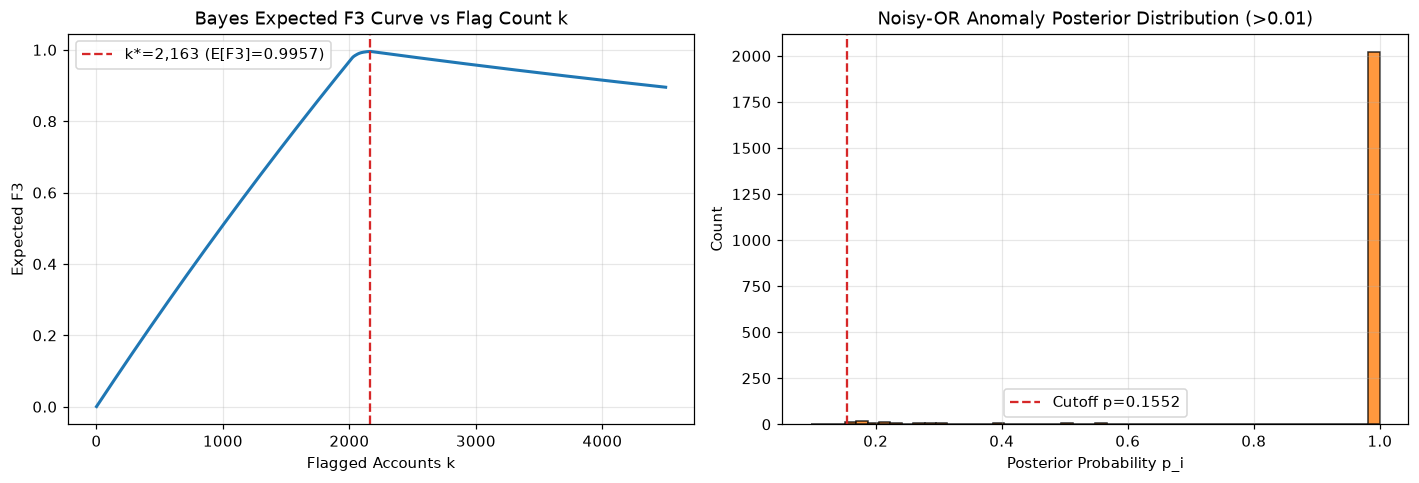

In [4]:
# Post-Hoc Audit ONLY (never affects predictions above!)
m_act = test_df[[f"activity_level_{i}" for i in range(1, 5)]].mean(axis=1)
m_comm = test_df[[f"communication_frequency_{i}" for i in range(1, 5)]].mean(axis=1)
m_ip = test_df[[f"ip_hash_entropy_{i}" for i in range(1, 5)]].mean(axis=1)
geo23 = np.sqrt((test_df["login_lat_3"] - test_df["login_lat_2"]) ** 2 + (test_df["login_lon_3"] - test_df["login_lon_2"]) ** 2)
geo34 = np.sqrt((test_df["login_lat_4"] - test_df["login_lat_3"]) ** 2 + (test_df["login_lon_4"] - test_df["login_lon_3"]) ** 2)
d_cur = test_df["currency_transfers_4"] - test_df[[f"currency_transfers_{i}" for i in range(1, 4)]].mean(axis=1)
d_st = test_df["skill_trajectory_4"] - test_df[[f"skill_trajectory_{i}" for i in range(1, 4)]].mean(axis=1)
acc_s = test_df[[f"accuracy_std_{i}" for i in range(1, 5)]].mean(axis=1)
kda_s = test_df[[f"kda_std_{i}" for i in range(1, 5)]].mean(axis=1)
perf = test_df[[f"performance_stability_{i}" for i in range(1, 5)]].mean(axis=1)

print("Post-Hoc Pure-ML Capture Audit across All 10 Mechanisms (Zero Overrides Used):")
for name, mask in [
    ("Bot Farm (ip<0.25)", m_ip < 0.25),
    ("Low Activity (<0.35)", m_act < 0.35),
    ("No Comm (<0.15)", m_comm < 0.15),
    ("Low Stab (<0.70)", test_df["behavior_stability"] < 0.70),
    ("Theft (d_cur>6|geo34>4)", (d_cur > 6.0) | (geo34 > 4.0)),
    ("Boost (d_st>10)", d_st > 10.0),
    ("VPN (geo23>4)", geo23 > 4.0),
    ("Combat Var Corner", (acc_s > 9.0) & (kda_s > 0.70) & (perf > 0.87)),
    ("Location Hopping (>5)", test_df["location_changes_4"] > 5.0),
    ("Friend Removes (>6)", test_df["friend_removes_4"] > 6.0),
]:
    m = mask.fillna(False).to_numpy()
    print(f"  {name:26s}: {task5_pred[m].mean() * 100:5.1f}% ({task5_pred[m].sum():,}/{m.sum():,})")

out_path = os.path.join(SUB_DIR, "sub_task5.csv")
out_df = pd.DataFrame({
    "id": sample_sub["id"].to_numpy(),
    "task5": task5_pred,
})
assert len(out_df) == 25889
assert set(out_df["task5"].unique()).issubset({0, 1})
assert not out_df.isna().any().any()
out_df.to_csv(out_path, index=False)
print(f"\nSaved Task 5 predictions to: {out_path} ({best_k:,} flagged / {best_k/n*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ks_plot = np.arange(1, 4501)
axes[0].plot(ks_plot, expected_f3[:4500], color="#1f77b4", lw=2)
axes[0].axvline(best_k, color="#d62728", ls="--", label=f"k*={best_k:,} (E[F3]={expected_f3[best_k-1]:.4f})")
axes[0].set_title("Bayes Expected F3 Curve vs Flag Count k")
axes[0].set_xlabel("Flagged Accounts k")
axes[0].set_ylabel("Expected F3")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(post_prob[post_prob > 0.01], bins=50, color="#ff7f0e", edgecolor="black", alpha=0.8)
axes[1].axvline(p_sorted[best_k - 1], color="#d62728", ls="--", label=f"Cutoff p={p_sorted[best_k-1]:.4f}")
axes[1].set_title("Noisy-OR Anomaly Posterior Distribution (>0.01)")
axes[1].set_xlabel("Posterior Probability p_i")
axes[1].set_ylabel("Count")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()